In [62]:
from algoshort.yfinance_handler import YFinanceDataHandler
from algoshort.ohlcprocessor import OHLCProcessor
from algoshort.wrappers import generate_signals, calculate_return
from algoshort.stop_loss import StopLossCalculator

from ta.breakout.bo_snapshot import build_snapshot
from ask_bo_trader import ask_bo_trader
from pipeline import (
    REGIME_COL,
    load_config,
    build_search_spaces,
    # load_data,
    # build_symbol_dfs,
    # compute_relative_prices,
    # generate_all_signals,
    # run_grid_search,
    # calculate_returns,
    # calculate_stop_losses,
    # calculate_position_sizing,
    # extract_cumul_snapshot,
    # save_results,
)

import rich

import logging
from pathlib import Path
from datetime import date 
import pandas as pd

logging.basicConfig(
    level=logging.WARNING,              # or DEBUG / WARNING / ERROR
    format="%(asctime)s [%(levelname)7s] %(name)s: %(message)s",
    datefmt="%Y-%m-%d %H:%M:%S",
)

stock = 'TCEHY'
benchmark = 'H4ZX.DE' # HSBC Hang Seng Tech UCITS ETF (H4ZX.DE)
fx = 'EURUSD=X' # EUR/USD exchange rate in us dollars

ticker_list = [stock, benchmark, fx]


massive_handler = YFinanceDataHandler(
    cache_dir="../data/ohlc/it",  # Cache directory
    enable_logging=True,
    chunk_size=20,                       # Smaller chunks for stability
    log_level=logging.INFO
)

today = date.today()

data = massive_handler.download_data(
    symbols=ticker_list,  # Example ticker
    start='2016-01-01',  # Start date for historical data
    # end='2026-02-20',    # End date for historical data
    end = today,
    # period='5y',           # 5 years of historical data
    interval='1d',         # Daily data
    use_cache=False,        # Use cache to avoid re-downloading
    threads=True           # Enable multi-threading
)

2026-04-26 07:23:50,695 - algoshort.yfinance_handler.YFinanceDataHandler - INFO - Cache hits: 0, Downloads needed: 3
2026-04-26 07:23:50,698 - algoshort.yfinance_handler.YFinanceDataHandler - INFO - Downloading 3 symbols in 1 chunks of 20
[*********************100%***********************]  3 of 3 completed
2026-04-26 07:23:50,995 - algoshort.yfinance_handler.YFinanceDataHandler - INFO - Successfully processed 3/3 symbols


In [63]:
CONFIG_PATH = Path("config.json")
cfg = load_config(CONFIG_PATH)
tt_search_space, bo_search_space, ma_search_space = build_search_spaces(cfg)

dfs = massive_handler.get_ohlc_data(stock)
bmk = massive_handler.get_ohlc_data(benchmark)
fx = massive_handler.get_ohlc_data(fx)

In [64]:
fx = fx.reset_index()
fx = fx.rename(columns={'close': 'fx_close'})
fx = fx[['date', 'fx_close']]

In [65]:
bmk_df = bmk.reset_index()
dfs = dfs.reset_index()

In [66]:
# filter rows from dfs where date is in bmk['date']
dfs = dfs[dfs['date'].isin(bmk_df['date'])]
dfs

,date,open,high,low,close,volume
1259,2021-01-04,66.371354,66.667817,65.356202,65.446037,3019600.0
1260,2021-01-05,67.467355,68.904741,67.332599,68.868813,2203000.0
1261,2021-01-06,68.536425,68.868824,65.401126,66.137787,4378100.0
1262,2021-01-07,65.580794,65.760464,64.493770,65.446037,6867700.0
1263,2021-01-08,65.742499,70.027707,65.589779,69.120361,10876700.0
...,...,...,...,...,...,...
2587,2026-04-20,66.809998,67.389999,66.500000,66.809998,2613600.0
2588,2026-04-21,66.230003,66.290001,65.029999,65.099998,3709500.0
2589,2026-04-22,65.019997,65.250000,64.129997,64.449997,4953300.0
2590,2026-04-23,63.180000,63.240002,61.619999,62.209999,9784500.0


In [67]:


# dfs = dfs.tail(len(bmk))



dfs = pd.merge(
    dfs, 
    fx, 
    how='left', 
    on='date'
)

dfs['close'] = dfs['close'] / dfs['fx_close']
dfs['low'] = dfs['low'] / dfs['fx_close']
dfs['high'] = dfs['high'] / dfs['fx_close']
dfs = dfs.drop(columns=['fx_close'])

processor = OHLCProcessor()
dfs = processor.calculate_relative_prices(dfs, bmk)

dfs, signal_columns = generate_signals(
    df=dfs,
    config_path='./config.json',
    tt_search_space=tt_search_space,
    bo_search_space=bo_search_space,
    ma_search_space=ma_search_space
)


dfs = calculate_return(dfs, signal_columns)

stop_loss_cfg: dict = cfg["stop_loss"]
calc = StopLossCalculator(dfs)

for signal in signal_columns:
    calc.data = calc.atr_stop_loss(
        signal=signal,
        window=stop_loss_cfg["atr_window"],
        multiplier=stop_loss_cfg["atr_multiplier"],
    )

dfs = calc.data
dfs["symbol"] = stock

In [68]:
dfs.columns.tolist()

['date',
 'open',
 'high',
 'low',
 'close',
 'volume',
 'ropen',
 'rhigh',
 'rlow',
 'rclose',
 'rhi_150',
 'rlo_150',
 'rbo_150',
 'rhi_50',
 'rlo_50',
 'rhi_20',
 'rlo_20',
 'rbo_50',
 'rbo_20',
 'rtt_5020',
 'rsma_short_50',
 'rsma_medium_100',
 'rsma_50100',
 'rsma_long_150',
 'rsma_100150',
 'rsma_50100150',
 'rema_short_50',
 'rema_medium_100',
 'rema_50100',
 'rema_long_150',
 'rema_100150',
 'rema_50100150',
 'rh1',
 'rl1',
 'rh2',
 'rl2',
 'rh3',
 'rl3',
 'rh4',
 'rl4',
 'rrg',
 'rflr',
 'rclg',
 'rrg_ch',
 'rbo_150_chg1D',
 'rbo_150_chg1D_fx',
 'rbo_150_PL_cum',
 'rbo_150_PL_cum_fx',
 'rbo_150_returns',
 'rbo_150_log_returns',
 'rbo_150_cumul',
 'rbo_50_chg1D',
 'rbo_50_chg1D_fx',
 'rbo_50_PL_cum',
 'rbo_50_PL_cum_fx',
 'rbo_50_returns',
 'rbo_50_log_returns',
 'rbo_50_cumul',
 'rbo_20_chg1D',
 'rbo_20_chg1D_fx',
 'rbo_20_PL_cum',
 'rbo_20_PL_cum_fx',
 'rbo_20_returns',
 'rbo_20_log_returns',
 'rbo_20_cumul',
 'rtt_5020_chg1D',
 'rtt_5020_chg1D_fx',
 'rtt_5020_PL_cum',
 'rtt

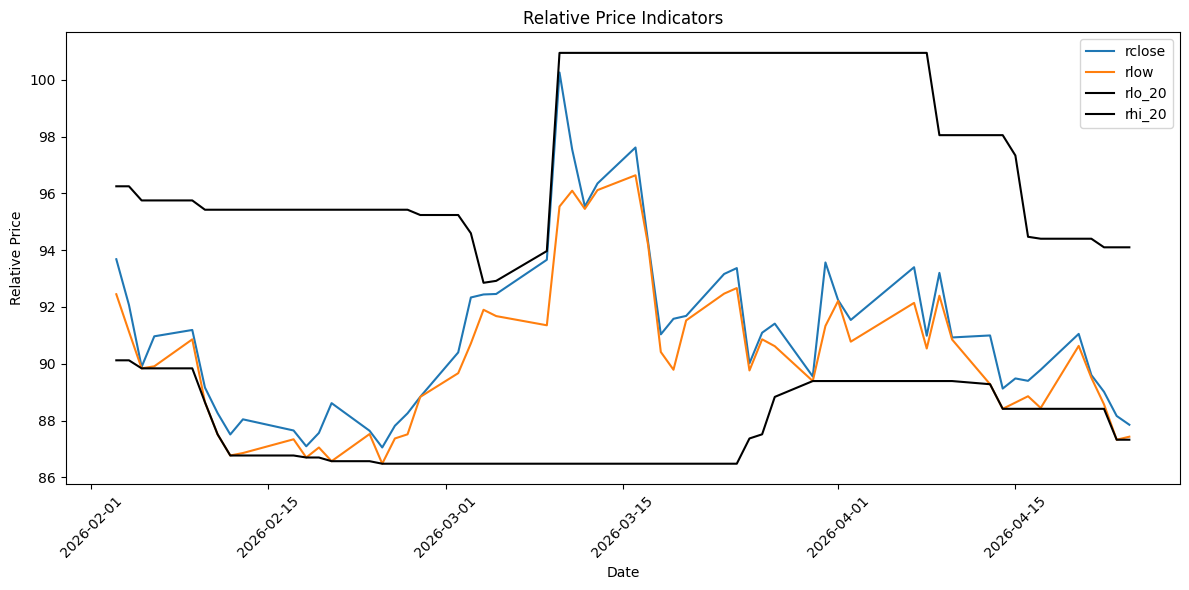

In [69]:
dfs[['date', 'rclose', 'rhigh', 'rhi_20', 'rh1', 'rh2', 'rh3', 'rh4', 'rbo_20']].tail(55)
dfs2 =dfs[['date', 'rclose', 'rlow', 'rlo_20', 'rhi_20']].tail(55)

# print from dfs2: date, rclose, rlow, rlo_20, rl1, rl2, rl3, rl4, rbo_20 in second axis
# create the plot with date on x-axis and rclose, rlow, rlo_20, rl1, rl2, rl3, rl4, rbo_20 on the second y-axis
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))
plt.plot(dfs2['date'], dfs2['rclose'], label='rclose')
plt.plot(dfs2['date'], dfs2['rlow'], label='rlow')
plt.plot(dfs2['date'], dfs2['rlo_20'], label='rlo_20', color='black')
plt.plot(dfs2['date'], dfs2['rhi_20'], label='rhi_20', color='black')
# plt.plot(dfs2['date'], dfs2['rl1'], label='rl1')
# plt.plot(dfs2['date'], dfs2['rl2'], label='rl2')
# plt.plot(dfs2['date'], dfs2['rl3'], label='rl3')
# plt.plot(dfs2['date'], dfs2['rl4'], label='rl4')
# plt.plot(dfs2['date'], dfs2['rbo_20'], label='rbo_20')
plt.xlabel('Date')
plt.ylabel('Relative Price')
plt.title('Relative Price Indicators')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [70]:
from ta.breakout.range_quality_plot import plot_range_quality 
import matplotlib.pyplot as plt 

2026-04-26 07:24:51,621 [WARNING] assess_range: skipped 2580 trailing non-zero bars to find the last consolidation window (limit=50). The ticker may be deep in an active trend; the zero-run found may be distant and unrepresentative.
2026-04-26 07:24:51,623 [WARNING] assess_range: 19 of 31 range_pct bars are NaN (61%). Likely caused by rhi_20 == rlo_20 (trading halt or stale data). Touch counts and sideways classification are based on 12 clean bars only.


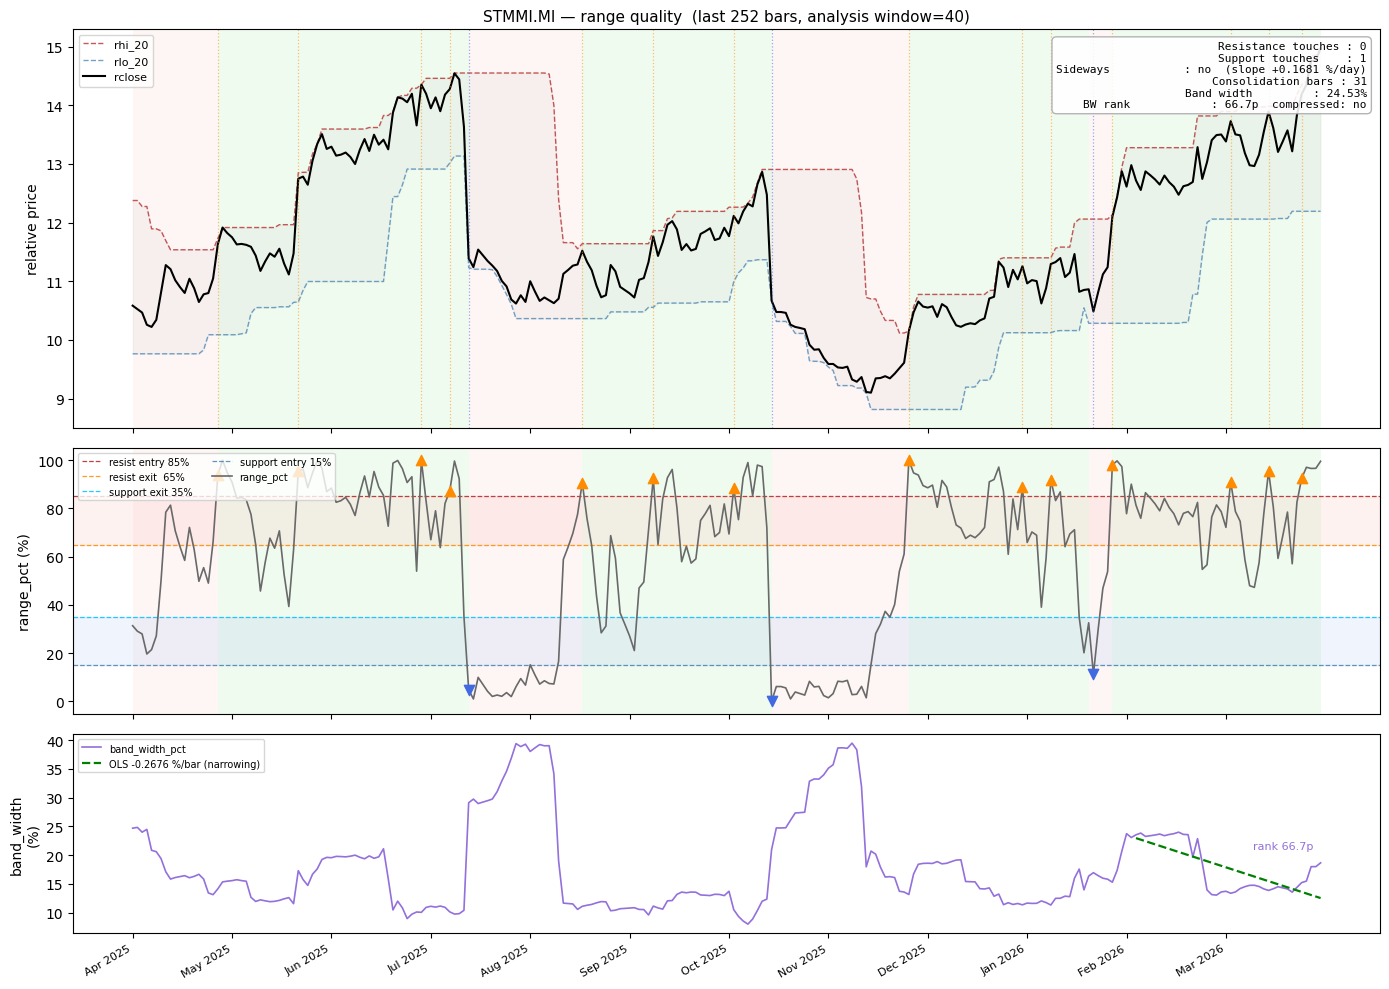

In [71]:
fig = plot_range_quality('STMMI.MI', plot_bars=252, window_bars=40)
plt.show() 

In [29]:


snapshot = build_snapshot(dfs)
bo_analysis =ask_bo_trader(snapshot, ticker=stock)
rich.print(bo_analysis)

2026-04-26 06:50:14,456 [WARNING] assess_range: skipped 1289 trailing non-zero bars to find the last consolidation window (limit=50). The ticker may be deep in an active trend; the zero-run found may be distant and unrepresentative.
2026-04-26 06:50:14,463 [WARNING] assess_range: 19 of 24 range_pct bars are NaN (79%). Likely caused by rhi_20 == rlo_20 (trading halt or stale data). Touch counts and sideways classification are based on 5 clean bars only.
2026-04-26 06:50:15,165 [INFO] Sending snapshot for TCEHY to gpt-4.1-nano (37 fields)
2026-04-26 06:50:23,125 [INFO] HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"


TraderAnalysis(
    description='TCEHY is in a bearish regime at -1, with the 150-day rel. outperformance declining (-7.61%). It 
exhibits a confluence of a short-term bearish breakout (-1,age 18, flip no) and a long-term position near 
resistance at 109 rhi with an active short \x12% from support at 102 rlo. Range setup shows a mature, sideways 
pattern with 24 consolidation bars and a narrow 15.98% width, but no resistance touches, hinting at a consolidating
phase. Volatility compression remains active with the range tightening (band width 7.61%) and a shallow downward 
slope, in a reliable 252-day history window. Volume trend is modestly expanding (1.22), but with declining 
activity, typical of a potential pause or preparatory phase.',
    regime=-1,
    confluence='full_short',
    short_term=TimeframeAnalysis(
        signal=-1,
        signal_age=18,
        fresh_flip=False,
        resistance=108.9142,
        support=102.2252,
        dist_to_resistance_pct=-0.65,
        dist_to_support_pct=-4.42,
        momentum_pct=-2.4,
        commentary='Short-term negative breakout signal with price near support, rbo_20 active but not flipped.'
    ),
    medium_term=TimeframeAnalysis(
        signal=1,
        signal_age=32,
        fresh_flip=False,
        resistance=117.2717,
        support=101.8866,
        dist_to_resistance_pct=33.48,
        dist_to_support_pct=-16.36,
        momentum_pct=-3.66,
        commentary='Medium-term shows consolidation with a positive momentum, but overall slight downward trend.'
    ),
    long_term=TimeframeAnalysis(
        signal=1,
        signal_age=232,
        fresh_flip=False,
        resistance=117.2717,
        support=74.505,
        dist_to_resistance_pct=33.48,
        dist_to_support_pct=-15.97,
        momentum_pct=-7.61,
        commentary='Long-term signals a major decline in relative strength, price below major resistance, with 
structural support at 75.'
    ),
    turtle=TurtleSignal(
        signal=0,
        aligned_with_rbo_20=False,
        commentary='Turtle channel is neutral, inside the range.'
    ),
    vol_trend=1.22,
    range_quality=RangeQuality(
        n_resistance_touches=0,
        n_support_touches=1,
        is_sideways=False,
        slope_pct_per_day=0.4816,
        consolidation_bars=24,
        band_width_pct=15.98,
        commentary='Range is mature, slightly drifting upwards, but not strongly sideways.'
    ),
    volatility_compression=VolatilityCompression(
        band_width_pct=7.61,
        band_width_slope=-0.127,
        band_width_pct_rank=20.24,
        is_compressed=True,
        commentary='Range is actively narrowing, suggesting energy buildup for a breakout.'
    ),
    volume_quality=VolumeQuality(
        vol_trend_mean=0.8641,
        vol_trend_slope=-0.031,
        is_quiet=True,
        is_declining=True,
        breakout_confirmed=None,
        commentary='Volume is quiet and declining within consolidation; no breakout confirmation.'
    ),
    risk=RiskLevels(
        long_stop=102.2252,
        long_structural_stop=101.8866,
        short_stop=108.9142,
        short_structural_stop=117.2717,
        peak_resistance=116.54,
        major_floor=74.505
    ),
    verdict='Scenario suggests a short bias with current short entry near support at 102, stop at 101.89, targeting
a move below recent support for continuation or a short reversal if resistance at 109/117 is tested.'
)

In [6]:
from agents import create_manager                                                                                                                                  
import json                                               

graph = create_manager(symbols_filter=["A2A.MI", "ENI.MI"], top_n=5)
result = graph.invoke({
      "symbols_filter": ["A2A.MI", "ENI.MI"],
      "top_n": 5,
      "data_source": "parquet",
      "benchmark": "FTSEMIB.MI",
      "fx": None,
})

assess_range failed: No consolidation window (rbo_20 == 0) found in the provided history. The entire series is in a trend or breakout state. Provide a longer history that includes at least one consolidation period.
assess_volume_profile failed: No consolidation window (signal_col == 0) found in the provided history. The entire series is in a trend or breakout state. Provide a longer history that includes at least one consolidation period.
assess_range failed: No consolidation window (rbo_20 == 0) found in the provided history. The entire series is in a trend or breakout state. Provide a longer history that includes at least one consolidation period.
assess_volume_profile failed: No consolidation window (signal_col == 0) found in the provided history. The entire series is in a trend or breakout state. Provide a longer history that includes at least one consolidation period.


In [7]:
payload = json.loads(result["payload_json"])
print(payload["n_symbols"])             # 2

2


In [8]:
snap = payload["breakout_snapshots"]["A2A.MI"]
print(snap)

{'date': '2026-04-14', 'rrg': 1.0, 'rclose': 1.079, 'rbo_150': 1.0, 'rbo_50': 1.0, 'rbo_20': -1.0, 'rhi_150': 1.321, 'rhi_50': 1.1714, 'rhi_20': 1.1684, 'rlo_150': 1.0338, 'rlo_50': 1.0523, 'rlo_20': 1.0751, 'rh3': 1.321, 'rh4': 1.3389, 'rl3': 1.0338, 'range_position_pct': 4.18, 'dist_to_rhi_150_pct': 22.43, 'dist_to_rhi_20_pct': 8.29, 'dist_to_rhi_50_pct': 8.56, 'dist_to_rlo_150_pct': 4.19, 'dist_to_rlo_20_pct': 0.36, 'dist_to_rlo_50_pct': 2.47, 'rclose_chg_150d': 3.39, 'rclose_chg_20d': -2.86, 'rclose_chg_50d': -5.82, 'rbo_20_age': 3, 'rbo_50_age': 55, 'rbo_150_age': 110, 'rbo_20_flip': 0, 'rbo_50_flip': 0, 'rbo_150_flip': 0, 'vol_trend': 0.75, 'rtt_5020': 0, 'range_setup': None, 'volatility_compression': {'band_width_pct': 8.6469, 'band_width_slope': -0.093994, 'band_width_pct_rank': 35.71, 'is_compressed': False, 'history_available': 252, 'is_rank_reliable': True}, 'volume_profile': None}


In [10]:
import rich
rich.print(result["breakout_result"])

{
    'top_symbols': [
        {
            'symbol': 'A2A.MI',
            'score': 0.35,
            'fresh_flip': False,
            'regime_aligned': True,
            'active_signals': ['rbo_150', 'rbo_50']
        },
        {
            'symbol': 'ENI.MI',
            'score': 0.35,
            'fresh_flip': False,
            'regime_aligned': True,
            'active_signals': ['rbo_150', 'rbo_50']
        }
    ],
    'signal_flips': [],
    'regime_aligned_count': 2
}

In [11]:
from agents._tools.prepare_tools import load_live_data
resolved_date, symbol_dfs = load_live_data(
    symbols=["TCEHY"],
    benchmark="H4ZX.DE",
    fx="EURUSD=X",
)
df = symbol_dfs["TCEHY"]
print(df.columns.tolist())   # confirm signal columns exist
print(df.tail(3))            # check last 3 bars

[*********************100%***********************]  3 of 3 completed
Missing benchmark data for 38 rows (2.8%). Values will be forward-filled. This may indicate misaligned date ranges.


['date', 'open', 'high', 'low', 'close', 'volume', 'ropen', 'rhigh', 'rlow', 'rclose', 'rhi_150', 'rlo_150', 'rbo_150', 'rhi_50', 'rlo_50', 'rhi_20', 'rlo_20', 'rbo_50', 'rbo_20', 'rtt_5020', 'rsma_short_50', 'rsma_medium_100', 'rsma_50100', 'rsma_long_150', 'rsma_100150', 'rsma_50100150', 'rema_short_50', 'rema_medium_100', 'rema_50100', 'rema_long_150', 'rema_100150', 'rema_50100150', 'rh1', 'rl1', 'rh2', 'rl2', 'rh3', 'rl3', 'rh4', 'rl4', 'rrg', 'rflr', 'rclg', 'rrg_ch', 'rbo_150_chg1D', 'rbo_150_chg1D_fx', 'rbo_150_PL_cum', 'rbo_150_PL_cum_fx', 'rbo_150_returns', 'rbo_150_log_returns', 'rbo_150_cumul', 'rbo_50_chg1D', 'rbo_50_chg1D_fx', 'rbo_50_PL_cum', 'rbo_50_PL_cum_fx', 'rbo_50_returns', 'rbo_50_log_returns', 'rbo_50_cumul', 'rbo_20_chg1D', 'rbo_20_chg1D_fx', 'rbo_20_PL_cum', 'rbo_20_PL_cum_fx', 'rbo_20_returns', 'rbo_20_log_returns', 'rbo_20_cumul', 'rtt_5020_chg1D', 'rtt_5020_chg1D_fx', 'rtt_5020_PL_cum', 'rtt_5020_PL_cum_fx', 'rtt_5020_returns', 'rtt_5020_log_returns', 'rtt_5

In [12]:
from ta.breakout.bo_snapshot import build_snapshot as bo_snap
from ta.ma.ma_snapshot import build_snapshot as ma_snap
snap_bo = bo_snap(df)
snap_ma = ma_snap(df)

assess_range failed: No consolidation window (rbo_20 == 0) found in the provided history. The entire series is in a trend or breakout state. Provide a longer history that includes at least one consolidation period.
assess_volume_profile failed: No consolidation window (signal_col == 0) found in the provided history. The entire series is in a trend or breakout state. Provide a longer history that includes at least one consolidation period.


In [14]:
snap_ma

{'date': '2026-04-23',
 'rrg': -1.0,
 'rclose': 5.2097,
 'rema_50100': 1.0,
 'rema_100150': -1.0,
 'rema_50100150': -1.0,
 'rsma_50100': 1.0,
 'rsma_100150': -1.0,
 'rsma_50100150': -1.0,
 'rema_short_50': 5.0491,
 'rema_medium_100': 5.0283,
 'rema_long_150': 5.0841,
 'rsma_short_50': 5.0726,
 'rsma_medium_100': 4.9505,
 'rsma_long_150': 4.9565,
 'rema_50100_stop_loss': 3.193,
 'rema_100150_stop_loss': 6.7113,
 'rema_50100150_stop_loss': 6.7113,
 'rh3': 6.1745,
 'rh4': None,
 'rl3': 5.3182,
 'rl4': None,
 'rema_100150_age': 250,
 'rema_50100150_age': 20,
 'rema_50100_age': 20,
 'rsma_100150_age': 229,
 'rsma_50100150_age': 35,
 'rsma_50100_age': 35,
 'rema_100150_flip': 0,
 'rema_50100150_flip': 0,
 'rema_50100_flip': 0,
 'rsma_100150_flip': 0,
 'rsma_50100150_flip': 0,
 'rsma_50100_flip': 0,
 'dist_to_rema_50_pct': -3.08,
 'dist_to_rema_100_pct': -3.48,
 'dist_to_rema_150_pct': -2.41,
 'dist_to_rsma_50_pct': -2.63,
 'dist_to_rsma_100_pct': -4.97,
 'dist_to_rsma_150_pct': -4.86,
 'rclo

In [17]:
from ask_bo_trader import ask_bo_trader

bo_result = ask_bo_trader(snap_bo, ticker="TCEHY")

2026-04-24 11:58:31,545 [INFO] Sending snapshot for TCEHY to gpt-4.1-nano (35 fields)
2026-04-24 11:58:40,159 [INFO] HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"


In [18]:
rich.print(bo_result)

TraderAnalysis(
    description="TCEHY's regime is bearish at -1, with a bearish 150-day and 50-day breakout signals (-1), but a 
short-term 20-day breakout (+1). The stock is significantly below all major resistance levels, with 
range_position_pct at -147.26%, indicating a deep selloff. Volatility compression is active with a narrow band 
width of 7.06%, slope -0.098, and a reliable percentile rank of 10.3, suggesting energy build-up for a potential 
reversal or continuation. Volume trends show low activity with a 0.28 ratio and no clear breakout confirmation.",
    regime=-1,
    confluence='full_short',
    short_term=TimeframeAnalysis(
        signal=1,
        signal_age=1,
        fresh_flip=True,
        resistance=6.1196,
        support=5.7516,
        dist_to_resistance_pct=17.47,
        dist_to_support_pct=-10.4,
        momentum_pct=4.12,
        commentary='Short-term rbo_20 signals a potential breakout above resistance at 6.1196, with a recent flip, 
but momentum remains weak.'
    ),
    medium_term=TimeframeAnalysis(
        signal=-1,
        signal_age=31,
        fresh_flip=False,
        resistance=6.1745,
        support=5.3182,
        dist_to_resistance_pct=18.52,
        dist_to_support_pct=-2.08,
        momentum_pct=5.56,
        commentary='Medium-term signals remain bearish, with price below resistance at 6.1745 and recent upward 
move, but no clear reversal.'
    ),
    long_term=TimeframeAnalysis(
        signal=-1,
        signal_age=238,
        fresh_flip=False,
        resistance=6.2508,
        support=5.3182,
        dist_to_resistance_pct=19.98,
        dist_to_support_pct=-2.08,
        momentum_pct=8.08,
        commentary='Long-term trend remains bearish with a 150-day breakout confirming downside extension; major 
resistance at 6.2508, major support at 5.3182.'
    ),
    turtle=TurtleSignal(
        signal=0,
        aligned_with_rbo_20=False,
        commentary='No turtle breakout signal in alignment with short-term rbo_20.'
    ),
    vol_trend=0.28,
    range_quality=RangeQuality(
        n_resistance_touches=2,
        n_support_touches=2,
        is_sideways=True,
        slope_pct_per_day=0.001,
        consolidation_bars=1,
        band_width_pct=7.06,
        commentary='Range appears very tight and active coiling, suggesting energy build-up but with recent flip in
short-term signal.'
    ),
    volatility_compression=VolatilityCompression(
        band_width_pct=7.06,
        band_width_slope=-0.098,
        band_width_pct_rank=10.3,
        is_compressed=True,
        commentary='Range energy is compressed and actively narrowing, indicating potential breakout energy 
accumulation.'
    ),
    volume_quality=VolumeQuality(
        vol_trend_mean=0.28,
        vol_trend_slope=-0.009,
        is_quiet=True,
        is_declining=True,
        breakout_confirmed=None,
        commentary='Volume remains quiet and declining; lack of breakout confirmation suggests cautious stance.'
    ),
    risk=RiskLevels(
        long_stop=5.7516,
        long_structural_stop=5.3182,
        short_stop=6.1196,
        short_structural_stop=6.2508,
        peak_resistance=6.1745,
        major_floor=5.3182
    ),
    verdict='Short bias with potential for a short-term transient move above 6.1196; consider short entry on 
breakout above resistance with stop at 6.1196, targeting 6.1745 resistance or below structural support at 5.3182.'
)